In [1]:
import pickle
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from scipy.special import softmax
from sklearn.model_selection import train_test_split

In [2]:
def load_cifar10_batch(filename):
    with open(filename, 'rb') as f:
        batch = pickle.load(f, encoding='bytes')
        X = batch[b'data']     # Already flattened to (N, 3072)
        Y = batch[b'labels']
        return X.astype('float32') / 255.0, np.array(Y)  # Normalize to [0,1]

In [3]:
# Path to dataset
data_dir = './'

# Load all training batches
X_train, y_train = [], []
for i in range(1, 6):
    file = os.path.join(data_dir, f'data_batch_{i}')
    X, y = load_cifar10_batch(file)
    X_train.append(X)
    y_train.append(y)

# Training set
X_train = np.vstack(X_train)  # Shape: (50000, 3072)
y_train = np.concatenate(y_train)

# Load test batch
X_test, y_test = load_cifar10_batch(os.path.join(data_dir, 'test_batch')) # Shape: (10000, 3072)

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Regularization strength: smaller C = stronger regularization
clf = LogisticRegression(
    penalty='l2',         # L2 regularization (default)
    C=10.0,                # Inverse of regularization strength (try e.g., 0.01, 0.1, 1.0, 10.0)
    solver='saga',        # Supports multinomial + L2 and large datasets
    multi_class='multinomial',
    max_iter=100          # May need to increase for convergence
)

# Fit the model
clf.fit(X_train, y_train)

In [ ]:
# Predict and evaluate
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {acc:.4f}")

In [4]:
onehot_encoder = OneHotEncoder(sparse=False)

In [53]:
# Define the projection argument for projected gradient descent
def projection(arr, lower_bound, upper_bound):
    return np.clip(np.asarray(arr), lower_bound, upper_bound)

def loss(X, Y, W):
    """
    Y: onehot encoded
    """
    Z = - X @ W
    N = X.shape[0]
    loss = 1/N * (np.trace(X @ W @ Y.T) + np.sum(np.log(np.sum(np.exp(Z), axis=1))))
    return loss

def gradient(X, Y, W, mu):
    """
    Y: onehot encoded 
    """
    Z = - X @ W
    P = softmax(Z, axis=1)
    N = X.shape[0]
    gd = 1/N * (X.T @ (Y - P)) + mu * W
    return gd

## Y is the labels, X is the data
def gradient_descent(X, Y, max_iter=4000, eta=0.01, mu=0.001):
    """
    Very basic gradient descent algorithm with fixed eta and mu
    """
    Y_onehot = onehot_encoder.fit_transform(Y.reshape(-1,1))
    W = np.ones((X.shape[1], Y_onehot.shape[1]))
    step = 0
    step_lst = [] 
    loss_lst = []
    W_lst = []
 
    while step < max_iter:
        step += 1
        W -= eta * gradient(X, Y_onehot, W, mu)
        step_lst.append(step)
        W_lst.append(W)
        loss_lst.append(loss(X, Y_onehot, W))

    df = pd.DataFrame({
        'step': step_lst, 
        'loss': loss_lst
    })
    return df, W, loss_lst[-1]

class Multiclass:
    def fit(self, X, Y):
        self.loss_steps, self.W, self.true_cost = gradient_descent(X, Y)

    def loss_plot(self):
        return self.loss_steps.plot(
            x='step', 
            y='loss',
            xlabel='step',
            ylabel='loss'
        )

    def predict(self, H):
        Z = - H @ self.W
        P = softmax(Z, axis=1)
        return np.argmax(P, axis=1)

In [ ]:
import time

start_time = time.time()

# fit model
model = Multiclass()
model.fit(X_train, y_train)

end_time = time.time()
elapsed_time = end_time - start_time
minutes = int(elapsed_time // 60)
seconds = elapsed_time % 60
print(f"Elapsed time: {minutes} minutes and {seconds:.2f} seconds")

In [ ]:
# plot loss
model.loss_plot()

# predict 
model.predict(X_test)

# check the predicted value and the actual value
# model.predict(X_test) == y_test
# Percentage of True values
accuracy = np.mean(model.predict(X_test) == y_test) * 100

print(f"Accuracy: {accuracy:.2f}%")

In [2]:
from sklearn.datasets import load_iris

C:\Users\yzhao654\AppData\Local\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


True cost is: 0.2056727320930122
Accuracy: 97.33%


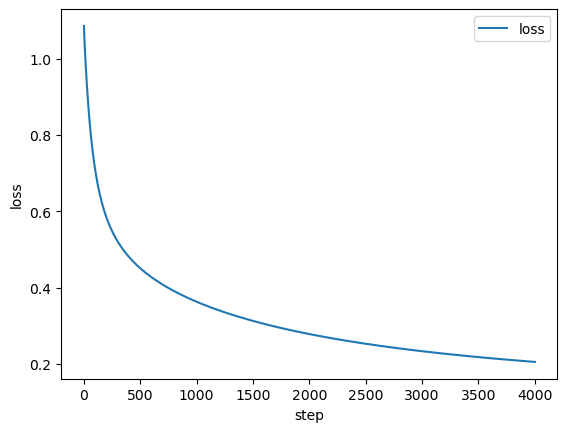

In [54]:
X = load_iris().data
Y = load_iris().target

# fit model
model = Multiclass()
model.fit(X, Y)

print(f"True cost is: {model.true_cost}")

# plot loss
model.loss_plot()

# predict 
model.predict(X)

# check the predicted value and the actual value
# model.predict(X_test) == y_test
# Percentage of True values
accuracy = np.mean(model.predict(X) == Y) * 100

print(f"Accuracy: {accuracy:.2f}%")

In [55]:
print(model.W)

[[ 0.33335102  0.42449237  2.12452435]
 [-0.51208612  1.22589215  2.16856171]
 [ 2.9649327   0.94650853 -1.02907349]
 [ 1.88752327  1.62671695 -0.63187248]]


In [95]:
import matplotlib.pyplot as plt

## Parameters for distributed implementation
N = 2 # agent number
comDelay = 0
upDelay = 1
lb = -5 # lower bound for projection 
ub = 5  # upper bound for projection 
mu = 1e-3

# Neighbor sets
neigh = np.tile(np.arange(0, N).reshape(-1, 1), (1, N))

K = 3 # number of classes

## Initial states 
num_samples, d = X.shape
x0 = np.ones((d, K, N)) # all 1's across all agents 
y0 = np.ones((d, K, N)) # all 1's across all agents 

## Hyperparameters
gamma = 3e-2
gammaHB = gamma * 2  
gammaNAG = gamma * 3  
gammaGM = gamma * 4
mu = 1e-3  # same as the lambd for now
lambdaHB = (gammaHB*mu)/2
lambdaNAG = (gammaNAG*mu)/(2*(1-gammaNAG*mu))
lambdaGM = (gammaGM*mu)/(2*(1-gammaGM*mu))*0.7 
betaGM =  (gammaGM*mu)/(2*(1-gammaGM*mu)) 

## Time vector (iterations)
dt = 0.1
tf = 1500 
tvec = np.arange(0, tf + dt, dt)

# Split the features equally across agents
features_per_agent = d // N   # perferably divided evenly 

# Divide the feature space for each agent
A_train = X
Y_onehot = onehot_encoder.fit_transform(Y.reshape(-1,1))
b_train = Y_onehot
A_train_list = []

start_idx = 0
for i in range(N):
    end_idx = start_idx + features_per_agent

    A_i = A_train[:, start_idx:end_idx]  # shape: (n, num_features)
    A_train_list.append(A_i)

    start_idx = end_idx

# Initializations
xvecGD = np.zeros((len(tvec)+1, d, K, N))
xvecHB = np.zeros((len(tvec)+1, d, K, N))
yvecHB = np.zeros((len(tvec)+1, d, K, N))
xvecNAG = np.zeros((len(tvec)+1, d, K, N))
yvecNAG = np.zeros((len(tvec)+1, d, K, N))
xvecGM = np.zeros((len(tvec)+1, d, K, N))
yvecGM = np.zeros((len(tvec)+1, d, K, N))


trueStateGD = np.ones((len(tvec), d, K))
trueStateHB = np.ones((len(tvec), d, K))
trueStateNAG = np.ones((len(tvec), d, K))
trueStateGM = np.ones((len(tvec), d, K))

# cost lists
cost_diffGD_lst = []
cost_diffHB_lst = []
cost_diffNAG_lst = []
cost_diffGM_lst = []
probs = [0.1]

if upDelay == 1:
    for prob in probs:
        probCom = prob * np.ones(N)

        # initialize x0 and y0
        xvecGD[0,:,:,:] = x0.copy() 
        xvecHB[0,:,:,:] = x0.copy()
        yvecHB[0,:,:,:] = y0.copy()
        xvecNAG[0,:,:,:] = x0.copy()
        yvecNAG[0,:,:,:] = y0.copy()
        xvecGM[0,:,:,:] = x0.copy()
        yvecGM[0,:,:,:] = y0.copy()

        for k in range(len(tvec)):
            upif = np.where(np.random.rand(N) < probCom)[0] if upDelay == 1 else np.arange(N)

            for n in range(N):
                ## Copy over
                xvecGD[k+1,:,:,n] = xvecGD[k,:,:,n] # copy over
                xvecHB[k+1,:,:,n] = xvecHB[k,:,:,n] # copy over
                yvecHB[k+1,:,:,n] = yvecHB[k,:,:,n] # copy over
                xvecNAG[k+1,:,:,n] = xvecNAG[k,:,:,n] # copy over
                yvecNAG[k+1,:,:,n] = yvecNAG[k,:,:,n] # copy over
                xvecGM[k+1,:,:,n] = xvecGM[k,:,:,n] # copy over
                yvecGM[k+1,:,:,n] = yvecGM[k,:,:,n] # copy over

            if len(upif) > 0:
                for cur_agent in upif:
                    # cur_agent is the current agent index

                    ####################################################### GD #############################################################################################
                    x_cur = xvecGD[k,:,:,cur_agent] # current agent's entire state vetor
                    x_block = x_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  
                    A_i = A_train_list[cur_agent]       # shape: (n, di)
                    # print(((b_train.reshape(-1,1) * (A_train @ x_cur))).shape)

                    Z = - A_train @ x_cur
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * x_block

                    # gd = 1/N * (X.T @ (Y - P)) + mu * W
                    # print(f"Gradient for agent {cur_agent} is:")
                    # print(gradif)
                    xnew_block = x_block - gamma * gradif # projected gradient descent
                    xvecGD[k+1,:,:,cur_agent] = x_cur # copy over first
                    xvecGD[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = xnew_block # update corresponding block for updating agent

                    ####################################################### HB #############################################################################################
                    x_cur = xvecHB[k,:,:,cur_agent] # current agent's entire state vetor (x)
                    y_cur = yvecHB[k,:,:,cur_agent] # current agent's entire state vetor (y)
                    ## Descent on y first 
                    x_block = x_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (x)
                    y_block = y_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (y)
    
                    Z = - A_train @ x_cur
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * x_block
                    
                    ynew_block = x_block - gammaHB * gradif + lambdaHB * (x_block-y_block) # projected gradient descent
                    yvecHB[k+1,:,:,cur_agent] = y_cur # copy over first
                    yvecHB[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = ynew_block # update corresponding block for updating agent

                    ## Descent on x
                    y_cur = yvecHB[k+1,:,:,cur_agent] # the current y is updated
                    y_block = y_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (y)

                    Z = - A_train @ y_cur
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * y_block
                    
                    xnew_block = y_block - gammaHB * gradif + lambdaHB * (y_block-x_block) # projected gradient descent
                    xvecHB[k+1,:,:,cur_agent] = x_cur # copy over first
                    xvecHB[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = xnew_block # update corresponding block for updating agent

                    ####################################################### NAG ############################################################################################
                    x_cur = xvecNAG[k,:,:,cur_agent] # current agent's entire state vetor (x)
                    y_cur = yvecNAG[k,:,:,cur_agent] # current agent's entire state vetor (y)
                    ## Descent on y first 
                    x_block = x_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (x)
                    y_block = y_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (y)
                    
                    # Momentum on x
                    x_momentum = x_cur + lambdaNAG*(x_cur-y_cur) # gradient is evaluated here
                    x_momentum_block = x_momentum[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block with momentum added (x)
                    
                    Z = - A_train @ x_momentum
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * x_momentum_block
                    
                    ynew_block = x_block - gammaNAG * gradif + lambdaNAG * (x_block-y_block) # projected gradient descent
                    yvecNAG[k+1,:,:,cur_agent] = y_cur # copy over first
                    yvecNAG[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = ynew_block # update corresponding block for updating agent

                    ## Descent on x
                    y_cur = yvecNAG[k+1,:,:,cur_agent] # the current y is updated
                    y_block = y_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (y)

                    # Momentum on y
                    y_momentum = y_cur + lambdaNAG*(y_cur-x_cur) # gradient is evaluated here
                    y_momentum_block = y_momentum[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block with momentum added (x)

                    Z = - A_train @ y_momentum
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * y_momentum_block
                    
                    xnew_block = y_block - gammaNAG * gradif + lambdaNAG * (y_block-x_block) # projected gradient descent
                    xvecNAG[k+1,:,:,cur_agent] = x_cur # copy over first
                    xvecNAG[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = xnew_block # update corresponding block for updating agent

                    ####################################################### GM #############################################################################################
                    x_cur = xvecGM[k,:,:,cur_agent] # current agent's entire state vetor (x)
                    y_cur = yvecGM[k,:,:,cur_agent] # current agent's entire state vetor (y)
                    ## Descent on y first 
                    x_block = x_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (x)
                    y_block = y_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (y)
                    
                    # Momentum on x
                    x_momentum = x_cur + lambdaGM*(x_cur-y_cur) # gradient is evaluated here
                    x_momentum_block = x_momentum[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block with momentum added (x)
                    
                    Z = - A_train @ x_momentum
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * x_momentum_block
                    
                    ynew_block = x_block - gammaGM * gradif + betaGM * (x_block-y_block) # projected gradient descent
                    yvecGM[k+1,:,:,cur_agent] = y_cur # copy over first
                    yvecGM[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = ynew_block # update corresponding block for updating agent

                    ## Descent on x
                    y_cur = yvecGM[k+1,:,:,cur_agent] # the current y is updated
                    y_block = y_cur[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block (y)

                    # Momentum on y
                    y_momentum = y_cur + lambdaGM*(y_cur-x_cur) # gradient is evaluated here
                    y_momentum_block = y_momentum[cur_agent * features_per_agent : (cur_agent + 1) * features_per_agent,:]  # current agent's local block with momentum added (x)

                    Z = - A_train @ y_momentum
                    P = softmax(Z, axis=1)
                    gradif = 1/num_samples * (A_i.T @ (b_train - P)) + mu * y_momentum_block
                    
                    xnew_block = y_block - gammaGM * gradif + betaGM * (y_block-x_block) # projected gradient descent
                    xvecGM[k+1,:,:,cur_agent] = x_cur # copy over first
                    xvecGM[k+1, cur_agent*features_per_agent :(cur_agent + 1)*features_per_agent,:,cur_agent] = xnew_block # update corresponding block for updating agent

            
            comif = np.where(np.random.rand(N) < probCom)[0] if comDelay == 1 else np.arange(N) # whether or not we need to communicate

            if len(comif) > 0:
                for cur_agent in comif:
                    sendto = np.intersect1d(np.arange(N), neigh[:,cur_agent])
                    sendto = sendto[sendto != cur_agent]
                    for ii in sendto:
                        # Send to neighbors
                        xvecGD[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = xvecGD[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
                        xvecHB[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = xvecHB[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
                        yvecHB[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = yvecHB[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
                        xvecNAG[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = xvecNAG[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
                        yvecNAG[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = yvecNAG[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
                        xvecGM[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = xvecGM[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
                        yvecGM[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, ii] = yvecGM[k+1, cur_agent*features_per_agent:(cur_agent + 1)*features_per_agent,:, cur_agent] # send local true states to neighbors
            else:
                for n in range(N):
                    xvecGD[k+1,:,:,n] = xvecGD[k,:,:,n] # copy over
                    xvecHB[k+1,:,:,n] = xvecHB[k,:,:,n] # copy over
                    yvecHB[k+1,:,:,n] = yvecHB[k,:,:,n] # copy over
                    xvecNAG[k+1,:,:,n] = xvecNAG[k,:,:,n] # copy over
                    yvecNAG[k+1,:,:,n] = yvecNAG[k,:,:,n] # copy over
                    xvecGM[k+1,:,:,n] = xvecGM[k,:,:,n] # copy over
                    yvecGM[k+1,:,:,n] = yvecGM[k,:,:,n] # copy over
            for agent in range(N):
                idx_start = agent * features_per_agent
                idx_end = (agent + 1) * features_per_agent
                
                trueStateGD[k, idx_start:idx_end,:] = xvecGD[k, idx_start:idx_end,:,agent]
                trueStateHB[k, idx_start:idx_end,:] = xvecHB[k, idx_start:idx_end,:,agent]
                trueStateNAG[k, idx_start:idx_end,:] = xvecNAG[k, idx_start:idx_end,:,agent]
                trueStateGM[k, idx_start:idx_end,:] = xvecGM[k, idx_start:idx_end,:,agent]
                
            ## true state is used to caluclate the true cost
            cost_diffGD_lst.append(loss(A_train, b_train, trueStateGD[k, :,:]) - model.true_cost)
            cost_diffHB_lst.append(loss(A_train, b_train, trueStateHB[k, :,:]) - model.true_cost)
            cost_diffNAG_lst.append(loss(A_train, b_train, trueStateNAG[k, :,:]) - model.true_cost)
            cost_diffGM_lst.append(loss(A_train, b_train, trueStateGM[k, :,:]) - model.true_cost)

            # print("Iteration:")
            # print(k+1)

        # print("True state (GD):")
        # print(x_star)
        # print("True state (TAGD):")
        # print(trueStateGD[-1,:]) 
        # print(f"True cost is: {cost_diffGD_lst[-1]}")
        

##############################################################################################################################

C:\Users\yzhao654\AppData\Local\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:868: FutureWarning: `sparse` was renamed to `sparse_output` in version 1.2 and will be removed in 1.4. `sparse_output` is ignored unless you leave `sparse` to its default value.
  warnings.warn(


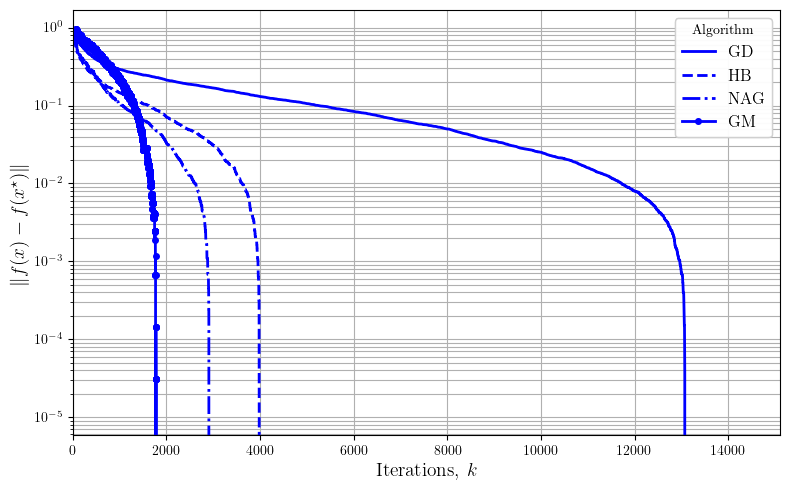

In [97]:
############################### Plotting block ###################################
from matplotlib.ticker import LogLocator, FuncFormatter

def log_format_func(x, pos):
    exponent = int(np.log10(x))
    return r'$10^{{{}}}$'.format(exponent)
    
# Set global font to Times New Roman and enable LaTeX
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['text.usetex'] = True  # Enable LaTeX rendering

# Color theme based on pp
pp = 1  # Change to 2, 3, or 4 for other color schemes
colors = {1: 'b', 2: 'r', 3: 'g', 4: 'm'}
c = colors.get(pp, 'k')

plt.figure(figsize=(8, 5))

# Plot GD and HB
line1, = plt.semilogy(np.arange(len(tvec)), cost_diffGD_lst, f'{c}-', linewidth=2, label='GD')
line2, = plt.semilogy(np.arange(len(tvec)), cost_diffHB_lst, f'{c}--', linewidth=2, label='HB')
line3, = plt.semilogy(np.arange(len(tvec)), cost_diffNAG_lst, f'{c}-.', linewidth=2, label='NAG')
line4, = plt.semilogy(np.arange(len(tvec)), cost_diffGM_lst, f'{c}-o', linewidth=2, markersize=4, label='GM')

# # Optional: probability markers
# p1, = plt.semilogy([], [], 'b*', markersize=8, markerfacecolor='b', linewidth=2, label=f'{probs[0]:.1f}')
# p2, = plt.semilogy([], [], 'r*', markersize=8, markerfacecolor='r', linewidth=2, label=f'{probs[1]:.1f}')
# p3, = plt.semilogy([], [], 'g*', markersize=8, markerfacecolor='g', linewidth=2, label=f'{probs[2]:.1f}')

# Labels and formatting
plt.xlabel(r'Iterations, $k$', fontsize=14)
plt.ylabel(r'$\|f(x) - f(x^\star)\|$', fontsize=14)
plt.xlim([0, len(tvec)+100])
plt.grid(True, which='both')

# Log scale formatting
ax = plt.gca()
ax.yaxis.set_major_locator(LogLocator(base=10.0))
ax.yaxis.set_major_formatter(FuncFormatter(lambda val, _: f'$10^{{{int(np.log10(val))}}}$' if val != 0 else '0'))

# Legends
legend1 = plt.legend([line1, line2, line3, line4], ['GD', 'HB', 'NAG', 'GM'], loc='upper right', fontsize=12, title='Algorithm')
# legend2 = plt.legend([p1, p2, p3], [f'{probs[0]:.1f}', f'{probs[1]:.1f}', f'{probs[2]:.1f}'],
#                      loc='upper right', fontsize=12, title='Probability')

# Add the main legend back
plt.gca().add_artist(legend1)
plt.tight_layout()
plt.savefig("Alg_comparison.png", dpi=300)
plt.show()